# 01 · Insertion physics: jack, chamfer, latch, compliance

The plug–jack interaction is what makes the task hard, so it's modelled explicitly instead of
being faked with a snap-to-goal.

* **Plug**: two boxes (body 11.7 × 8 × 21 mm + boot), 12 g, the last link of the cable chain.
* **Jack**: a rectangular channel (plug + `clearance`) and a back stop. Each side is **one convex
  wedge mesh**: a 45° lead-in bevel (`chamfer`, protruding in front of the face) merged with the
  channel wall.
* **Latch**: a detent force (up to 10 N) resists the last 5 mm. At `seat_depth`, if the plug is
  aligned, a weld constraint switches on (the "click"). A plug let go before the click is pushed
  back out.
* **Compliant insertion**: an action bit puts the arm controller in an impedance-like mode: stiff
  along the insertion axis, soft laterally and in rotation, **centred at the plug tip** (a
  remote-centre-compliance wrist). The push force is bounded.

What we found while tuning this (and why the defaults are what they are):
1. MuJoCo combines friction with **max(geom1, geom2)**. A grippy plug (μ = 0.8) made the 45°
   chamfer self-locking for low plugs, so plug and jack use μ ≈ 0.3 and the finger pads (1.5)
   still govern the grasp.
2. With a stiff position-controlled arm, a lateral error of about 1 mm turns the axial push into a
   moment that twists the plug in the fingers and wedges it. Compliance centred at the tip fixes
   most of this. The scripted expert's back-off-and-spiral retry handles the rest.
3. Building the funnel from separate boxes (chamfer plate + wall + face plate) left internal
   corners. Under the push, the plug edge sank a few tenths of a mm into the chamfer, met the face
   plate behind it (contact normal pointing straight back) and jammed, mostly for low plugs. One
   convex wedge per side removes those corners. Contact softness still widens the effective funnel
   by ≈0.5 mm, and the cable's pull shifts it by ≈0.5 mm.
4. The controller runs between `mj_step1` and `mj_step2`, and its mode is part of the action, so
   **restore(state) + replay(actions) is bit-exact** (last cell).

In [1]:
# Setup cell, inlined into every notebook by notebooks/build.py.
# Locally: finds the repo. On a Colab runtime (also VS Code connected to Colab), where the code is not
# on the VM: fetches it from (1) PLUGSIM_REPO (git URL, default: the public repo), (2) /content/RobotPluggingSim.zip, or
# (3) MyDrive/RobotPluggingSim (Drive), installs it, and keeps data/ + runs/ on Drive when mounted.
import os, sys, pathlib, subprocess
DEFAULT_REPO = "https://github.com/carlo-scr/RobotPluggingSim.git"
PLUGSIM_REPO = os.environ.get("PLUGSIM_REPO") or DEFAULT_REPO  # Colab: code is cloned from here
USE_DRIVE = os.environ.get("PLUGSIM_DRIVE", "1") == "1"  # set False if drive.mount hangs in your client
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if IN_COLAB:
    # numpy's BLAS: one thread (the sim solves tiny systems; extra threads only add contention)
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("MUJOCO_GL", "egl")
    os.environ.setdefault("PYOPENGL_PLATFORM", "egl")
    # Colab ships the NVIDIA driver but not its EGL vendor file, so EGL silently falls back to CPU
    # (software) rendering, ~100x slower. Register the NVIDIA EGL library (as in MuJoCo's Colab tutorial).
    _icd = pathlib.Path("/usr/share/glvnd/egl_vendor.d/10_nvidia.json")
    if subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0 and not _icd.exists():
        _icd.parent.mkdir(parents=True, exist_ok=True)
        _icd.write_text('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}\n')
        print("registered the NVIDIA EGL vendor file (GPU rendering)")
    CODE = pathlib.Path("/content/RobotPluggingSim")
    DRIVE = pathlib.Path("/content/drive/MyDrive")
    if (CODE / ".git").exists():
        subprocess.run(["git", "-C", str(CODE), "pull", "-q"])  # pick up pushed changes
    if not (CODE / "plugsim").exists():
        if PLUGSIM_REPO:
            subprocess.run(["git", "clone", "-q", PLUGSIM_REPO, str(CODE)], check=True)
        elif pathlib.Path("/content/RobotPluggingSim.zip").exists():
            subprocess.run(["unzip", "-q", "-o", "/content/RobotPluggingSim.zip", "-d", "/content"], check=True)
    if USE_DRIVE and not DRIVE.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:  # e.g. not supported by the client; fine with PLUGSIM_REPO or the zip
            print("Drive not mounted:", e)
    if not (CODE / "plugsim").exists():
        if (DRIVE / "RobotPluggingSim").exists():
            subprocess.run(["rsync", "-a", "--exclude", ".venv", "--exclude", "data", "--exclude", "runs", "--exclude", "media",
                            f"{DRIVE}/RobotPluggingSim/", f"{CODE}/"], check=True)
        else:  # last resort: the public repo
            subprocess.run(["git", "clone", "-q", DEFAULT_REPO, str(CODE)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(CODE)], check=True)
    if DRIVE.exists():  # persist datasets and checkpoints across sessions / notebooks
        for d in ("data", "runs"):
            tgt = DRIVE / "plugsim_runs" / d
            tgt.mkdir(parents=True, exist_ok=True)
            link = CODE / d
            if not link.is_symlink():
                subprocess.run(["rm", "-rf", str(link)])
                link.symlink_to(tgt)
    else:
        print("WARNING: no Drive: data/ and runs/ live on the VM and are lost when the runtime stops")
    try:
        import torch
        if torch.cuda.is_available():
            os.environ.setdefault("PLUGSIM_SCALE", "a100")
    except ImportError:
        pass
    os.chdir(CODE)
ROOT = pathlib.Path.cwd()
while not (ROOT / "plugsim").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")  # headless GPU nodes
print("ROOT:", ROOT, "| colab:", IN_COLAB, "| scale:", os.environ.get("PLUGSIM_SCALE", "local"))

ROOT: . | colab: False | scale: local


In [2]:
import os, sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
from plugsim.config import EnvCfg
from plugsim.env import PlugEnv
from plugsim.expert import ScriptedExpert
from plugsim.tools import clone_expert, restore_expert, run_until, finish, plug_port_force, image_grid

# Grid resolution: small for a laptop. On an H100 node bump these up (each rollout is independent).
GRID = np.linspace(-2.5e-3, 2.5e-3, 11)
SEED = 5

## Close-up of the jack
A third-person close-up of the target port before and during insertion.

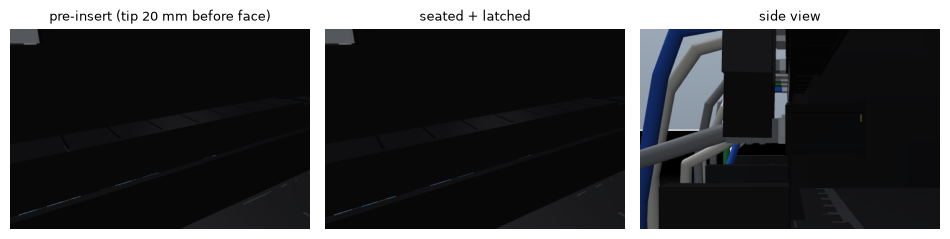

In [3]:
env = PlugEnv(EnvCfg())
env.reset(seed=SEED); ex = ScriptedExpert(env, seed=SEED)
port = env.port_pose(env.scenario.port_idx)[0]
imgs = []
run_until(env, ex, "insert")
imgs.append(env.render_free(lookat=port, distance=0.12, azimuth=150, elevation=-20, width=480, height=320))
finish(env, ex, until=("hold",))
imgs.append(env.render_free(lookat=port, distance=0.12, azimuth=150, elevation=-20, width=480, height=320))
imgs.append(env.render_free(lookat=port, distance=0.08, azimuth=90, elevation=0, width=480, height=320))
image_grid(imgs, ["pre-insert (tip 20 mm before face)", "seated + latched", "side view"], cols=3); plt.show()

## Insertion funnel: success vs lateral pre-insert error
Branching from one saved state: run the expert to the start of `align`, snapshot, then give it a
biased belief of where the port is (dy, dz) and let it insert **without retries**. Each cell is one
rollout. Left: compliant insertion (default). Right: the same with stiff position control.

242 rollouts in 194s


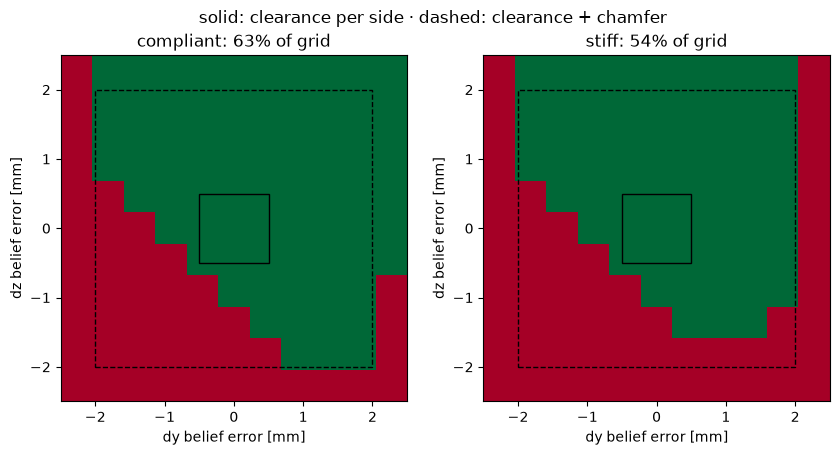

In [4]:
def funnel_map(env, seed, grid, compliant=True, retries=0, clearance=None):
    env.reset(seed=seed); ex = ScriptedExpert(env, seed=seed, noise=False)
    run_until(env, ex, "align")
    snap, exs = env.get_state(), clone_expert(ex)
    out = np.zeros((len(grid), len(grid)))
    for i, dz in enumerate(grid):
        for j, dy in enumerate(grid):
            env.set_state(snap); restore_expert(ex, exs)
            ex.port_noise_yz = np.array([dy, dz]); ex.max_retries = retries
            ex.COMPLIANT_PHASES = ScriptedExpert.COMPLIANT_PHASES if compliant else ()
            ex._start("align")
            out[i, j] = finish(env, ex, until=("release",))
    return out

t = time.time()
maps = {c: funnel_map(env, SEED, GRID, compliant=c) for c in (True, False)}
print(f"{2 * len(GRID) ** 2} rollouts in {time.time() - t:.0f}s")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ext = [GRID[0] * 1e3, GRID[-1] * 1e3, GRID[0] * 1e3, GRID[-1] * 1e3]
half = (env.cfg.port.clearance / 2) * 1e3; ch = half + env.cfg.port.chamfer * 1e3
for ax, (c, mp) in zip(axes, maps.items()):
    ax.imshow(mp, origin="lower", extent=ext, cmap="RdYlGn", vmin=0, vmax=1)
    for r, ls in ((half, "-"), (ch, "--")):
        ax.add_patch(plt.Rectangle((-r, -r), 2 * r, 2 * r, fill=False, ls=ls, color="k"))
    ax.set_title(f"{'compliant' if c else 'stiff'}: {mp.mean():.0%} of grid")
    ax.set_xlabel("dy belief error [mm]"); ax.set_ylabel("dz belief error [mm]")
fig.suptitle("solid: clearance per side · dashed: clearance + chamfer"); plt.show()

## Clearance sweep
How the tolerance shapes difficulty: success vs radial belief error for several clearances
(6 directions per radius, compliant mode, no retries). Tightening towards the real ~0.3–0.5 mm
makes the task harder, and the chamfer does more of the work.

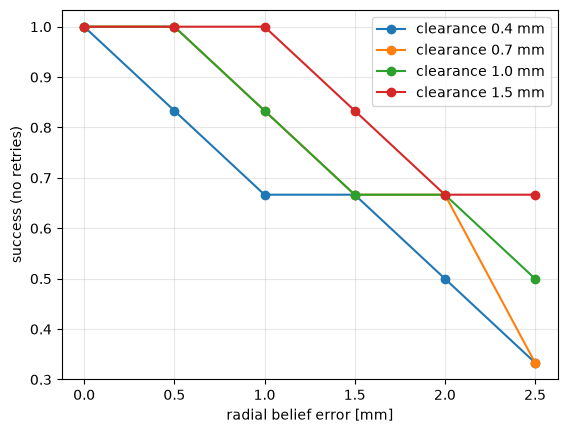

In [5]:
radii = np.array([0, 0.5, 1.0, 1.5, 2.0, 2.5]) * 1e-3
dirs = np.linspace(0, 2 * np.pi, 6, endpoint=False)
res = {}
for clr in (0.0004, 0.0007, 0.0010, 0.0015):
    c = EnvCfg(); c.port.clearance = clr
    e = PlugEnv(c, render=False)
    e.reset(seed=SEED); ex = ScriptedExpert(e, seed=SEED, noise=False)
    run_until(e, ex, "align"); snap, exs = e.get_state(), clone_expert(ex)
    rate = []
    for r in radii:
        ok = []
        for a in (dirs if r > 0 else [0.0]):
            e.set_state(snap); restore_expert(ex, exs)
            ex.port_noise_yz = r * np.array([np.cos(a), np.sin(a)]); ex.max_retries = 0
            ex._start("align"); ok.append(finish(e, ex, until=("release",)))
        rate.append(np.mean(ok))
    res[clr] = rate
for clr, rate in res.items():
    plt.plot(radii * 1e3, rate, "o-", label=f"clearance {clr * 1e3:.1f} mm")
plt.xlabel("radial belief error [mm]"); plt.ylabel("success (no retries)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## Force / depth profile of one nominal insertion
Axial contact force from the jack on the plug, plus the latch detent, against insertion depth.

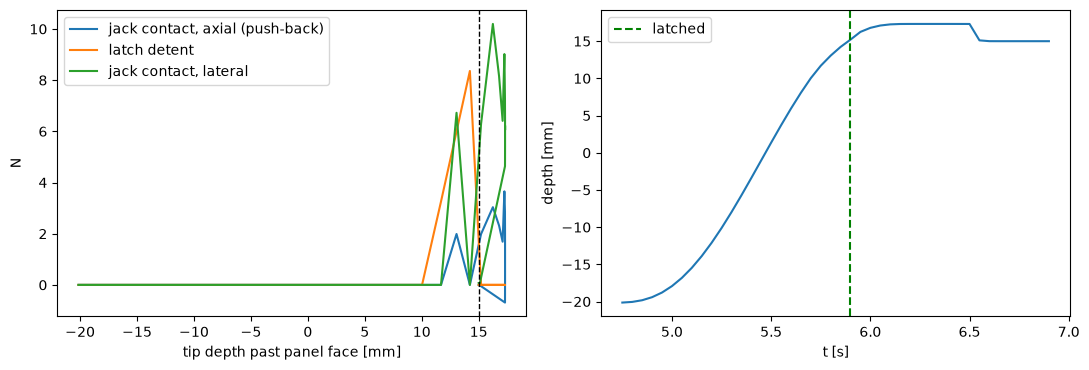

latched port 34 | target 34 | retries 0


In [6]:
env.reset(seed=SEED); ex = ScriptedExpert(env, seed=SEED)
run_until(env, ex, "insert")
log = []
def cb(e, x, a):
    pr = e.privileged()
    f = plug_port_force(e)
    det = e.data.xfrc_applied[e.plug_body, 0]
    log.append((e.time, pr["depth"], f[0], np.linalg.norm(f[1:]), det, pr["latched_port"] >= 0))
finish(env, ex, until=("retreat",), callback=cb)
L = np.array(log, float)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(L[:, 1] * 1e3, -L[:, 2], label="jack contact, axial (push-back)")
ax[0].plot(L[:, 1] * 1e3, -L[:, 4], label="latch detent")
ax[0].plot(L[:, 1] * 1e3, L[:, 3], label="jack contact, lateral")
ax[0].axvline(env.cfg.port.seat_depth * 1e3, color="k", ls="--", lw=1); ax[0].set_xlabel("tip depth past panel face [mm]"); ax[0].set_ylabel("N"); ax[0].legend()
ax[1].plot(L[:, 0], L[:, 1] * 1e3); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("depth [mm]")
lt = L[np.argmax(L[:, 5] > 0), 0] if L[:, 5].any() else None
if lt: ax[1].axvline(lt, color="g", ls="--", label="latched"); ax[1].legend()
plt.tight_layout(); plt.show()
print("latched port", env.latched_port, "| target", env.scenario.port_idx, "| retries", ex.retries)

## Determinism: restore + replay is exact
This is what makes counterfactual experiments possible, e.g. the RQ1 oracle test: "from this
saved state, execute each of K candidate action chunks and see which one succeeds".

In [7]:
from plugsim.datagen import EpisodeSpec, run_episode
ep = run_episode(env, EpisodeSpec(seed=11), cameras=[])
st = ep["data"]["state"]; n = len(st)
for k in (0, n // 2, n - 30):
    env.set_state(dict(physics=ep["physics"][k], aux=ep["aux"][k]))
    dev = 0.0
    for j in range(k, n - 1):
        env.step(ep["actions64"][j]); dev = max(dev, np.abs(env.observe() - st[j + 1]).max())
    print(f"restore at step {k:3d}, replay {n - 1 - k:3d} steps -> max |state deviation| = {dev:.1e}")

restore at step   0, replay 178 steps -> max |state deviation| = 0.0e+00


restore at step  89, replay  89 steps -> max |state deviation| = 0.0e+00
restore at step 149, replay  29 steps -> max |state deviation| = 0.0e+00
